# v2 — Notebook 05 · Multi-country reasoning (the interpretation layer)

**Where we are:** notebook 04 detects *when* trade is abnormal. This notebook explains *what* and
*who*: when several countries move abnormally in the same month, was it a **shared shock** (the whole
region together) or an **isolated** one-country event?

**Why this matters for the project**
- It is the **novelty seed**: most anomaly systems say "anomaly at time t"; few explain it across
  many sensors/countries.
- It is the **bridge to the LLM**: every number here is computed by code (counts, z-scores,
  fractions). The language model later only *phrases* this — it never invents the facts. That keeps
  answers **trust-aware** (computed vs inferred).

Logic in `src/reasoning.py`; this notebook imports and demonstrates it.
> ⚠️ v2 = international trade.

## Step 0 · Setup

In [1]:
import sys
from pathlib import Path
def find_v2_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "src" / "reasoning.py").exists():
            return base
    raise FileNotFoundError("v2 root not found")
V2 = find_v2_root(); sys.path.insert(0, str(V2))
DATA = V2.parent / "data" / "eu_trade_monthly.csv"

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110
from src import preprocess as pp
from src import reasoning as rz

logged = pp.log_transform(pp.load_trade(DATA))
cz = rz.cross_section_z(logged, flow="_EXP")     # months x 27 countries, standardised growth
print("cross-section z:", cz.shape, "(rows=months, cols=countries)")

cross-section z: (292, 27) (rows=months, cols=countries)


## Step 1 · The cross-section — every country, every month, on one scale

**What:** a heatmap of standardised year-on-year export growth. Each row is a month, each column a
country. **Why:** anomalies that span a whole *row* (many countries at once) are systemic; a single
hot cell is isolated. **How to read:** deep red rows = everyone collapsing together (the crises);
deep blue rows = everyone surging (rebounds).

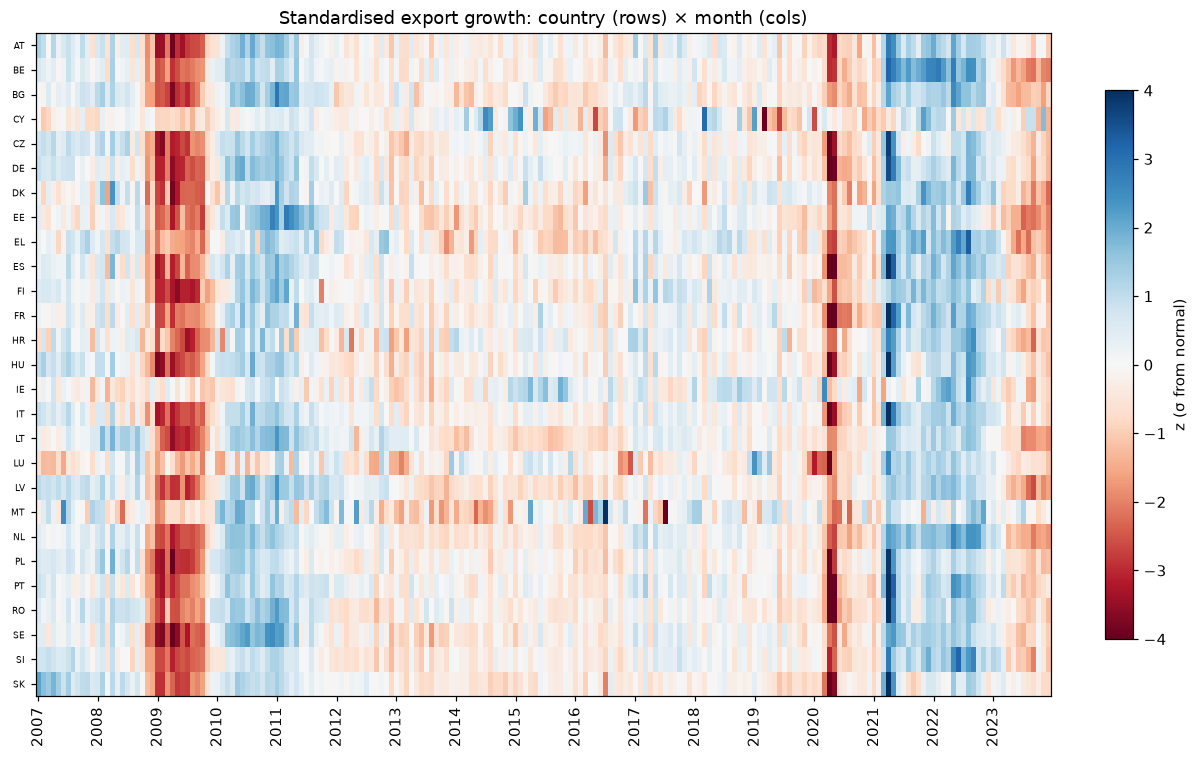

Vertical red bands = months where MANY countries dropped together (2009, 2020).


In [2]:
sub = cz.loc["2007":"2023"]                      # focus window for readability
fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(sub.T, aspect="auto", cmap="RdBu", vmin=-4, vmax=4)
ax.set_yticks(range(len(sub.columns))); ax.set_yticklabels(sub.columns, fontsize=6)
xt = range(0, len(sub.index), 12)
ax.set_xticks(list(xt)); ax.set_xticklabels([sub.index[i].year for i in xt], rotation=90)
ax.set_title("Standardised export growth: country (rows) × month (cols)")
fig.colorbar(im, fraction=.025, label="z (σ from normal)")
plt.tight_layout(); plt.show()
print("Vertical red bands = months where MANY countries dropped together (2009, 2020).")

## Step 2 · Systemic timeline — how many countries are abnormal each month?

**What:** count countries with |z| ≥ 2 each month. **Why:** this single line turns the heatmap into
a 'how systemic was it?' signal. **How to read:** tall bars = whole-region events.

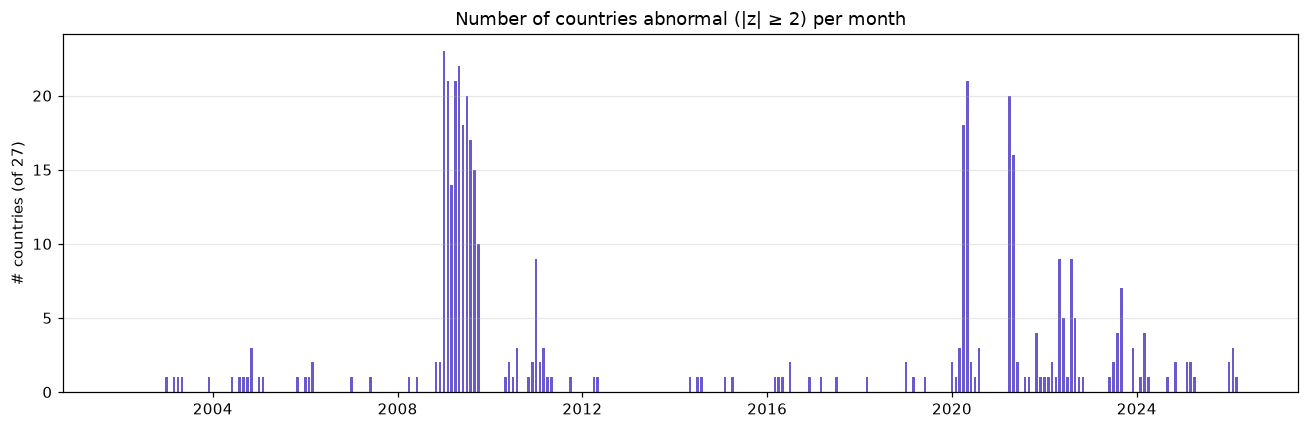

Biggest systemic months:
month
2009-01-01    23
2009-05-01    22
2020-05-01    21
2009-04-01    21
2009-02-01    21


In [3]:
counts = rz.systemic_timeline(cz, thresh=2.0)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(counts.index, counts.values, width=20, color="slateblue")
ax.set_title("Number of countries abnormal (|z| ≥ 2) per month")
ax.set_ylabel("# countries (of 27)"); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()
print("Biggest systemic months:")
print(counts.sort_values(ascending=False).head(5).to_string())

## Step 3 · Explain a SHARED shock — April 2020 (COVID)

**What:** break down one systemic month — who moved, how far, same direction? **Why:** this is the
reasoning output a user would read. **How to read:** most countries down together = a shared shock.

2020-04-01: 18/27 countries abnormal, mostly down — a shared shock. Largest moves: FR (-5.4σ), RO (-5.4σ), IT (-5.2σ), SK (-5.1σ), ES (-5.0σ).

evidence: 18 down / 0 up of 27; fraction 67% -> classified 'shared shock'.


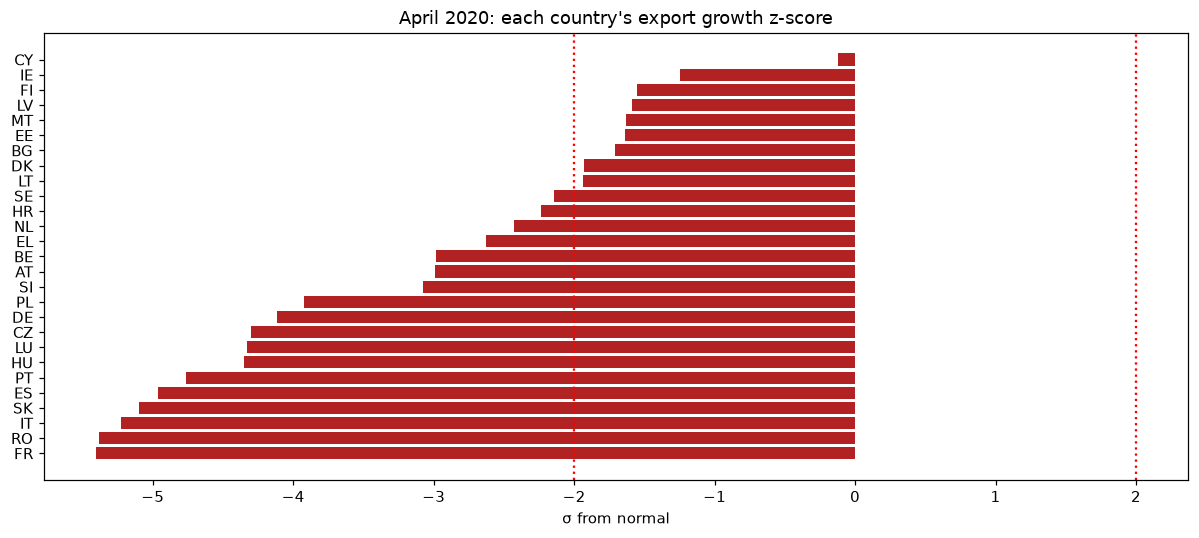

In [4]:
rep = rz.explain_month(cz, "2020-04-01", thresh=2.0)
print(rep.sentence())
print(f"\nevidence: {rep.n_down} down / {rep.n_up} up of {rep.n_total}; "
      f"fraction {rep.fraction:.0%} -> classified '{rep.kind}'.")

br = rz.month_breakdown(cz, "2020-04-01")
fig, ax = plt.subplots(figsize=(11, 5))
colors = ["firebrick" if v < 0 else "seagreen" for v in br.values]
ax.barh(br.index, br.values, color=colors)
ax.axvline(-2, color="red", ls=":"); ax.axvline(2, color="red", ls=":")
ax.set_title("April 2020: each country's export growth z-score"); ax.set_xlabel("σ from normal")
plt.tight_layout(); plt.show()

## Step 4 · Contrast — an ISOLATED, single-country month

**What:** automatically find a month where only *one* country was abnormal, and show it. **Why:** to
prove the reasoning distinguishes systemic from idiosyncratic — not everything is a shared shock.
**How to read:** one bar past the line = a country-specific event, not a regional one.

Isolated months found: 57
2014-08-01: 1/27 countries abnormal, mostly up — a isolated. Largest moves: CY (+2.2σ).


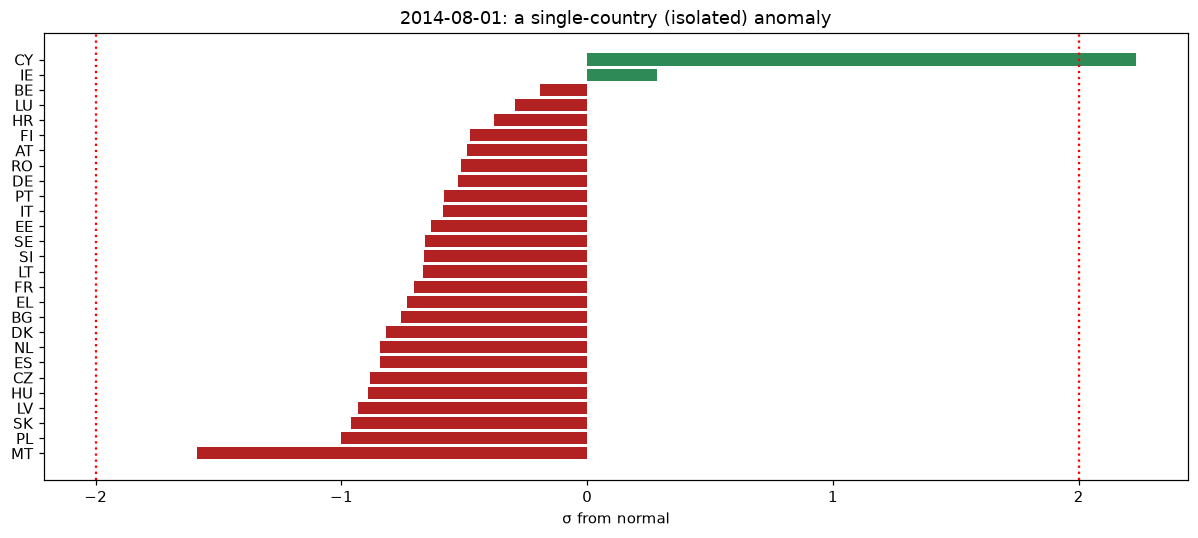

In [5]:
iso_months = rz.find_isolated_months(cz, thresh=2.0)
pick = iso_months[len(iso_months)//2]            # a representative isolated month
rep_iso = rz.explain_month(cz, pick, thresh=2.0)
print("Isolated months found:", len(iso_months))
print(rep_iso.sentence())

br = rz.month_breakdown(cz, pick)
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(br.index, br.values, color=["firebrick" if v < 0 else "seagreen" for v in br.values])
ax.axvline(-2, color="red", ls=":"); ax.axvline(2, color="red", ls=":")
ax.set_title(f"{pick.date()}: a single-country (isolated) anomaly"); ax.set_xlabel("σ from normal")
plt.tight_layout(); plt.show()

## Step 5 · Trust-aware explanation — the bridge to the LLM

**What:** assemble a structured answer that separates **computed facts** (🔢) from **inference** (🧠).
**Why:** this is exactly what the LLM will receive — it may rephrase the 🔢 facts but must never
change them, and any 🧠 cause is clearly labelled as interpretation, not measurement.

In [6]:
def trust_answer(cz, month, hint=None):
    r = rz.explain_month(cz, month, thresh=2.0)
    lines = [f"🔢 COMPUTED — {month}: {r.n_down+r.n_up}/{r.n_total} countries abnormal "
             f"({r.direction}), fraction {r.fraction:.0%}, kind = {r.kind}.",
             "🔢 COMPUTED — largest moves: " + ", ".join(f"{c} {z:+.1f}σ" for c, z in r.top)]
    if hint:
        lines.append(f"🧠 INFERRED — likely cause: {hint} (context, not measured).")
    return "\n".join(lines)

print(trust_answer(cz, "2020-04-01", hint="COVID-19 lockdowns halting trade"))
print()
print(trust_answer(cz, "2009-01-01", hint="global financial crisis"))

🔢 COMPUTED — 2020-04-01: 18/27 countries abnormal (down), fraction 67%, kind = shared shock.
🔢 COMPUTED — largest moves: FR -5.4σ, RO -5.4σ, IT -5.2σ, SK -5.1σ, ES -5.0σ
🧠 INFERRED — likely cause: COVID-19 lockdowns halting trade (context, not measured).

🔢 COMPUTED — 2009-01-01: 23/27 countries abnormal (down), fraction 85%, kind = shared shock.
🔢 COMPUTED — largest moves: HU -3.8σ, SE -3.6σ, AT -3.5σ, CZ -3.3σ, ES -3.3σ
🧠 INFERRED — likely cause: global financial crisis (context, not measured).


## Step 6 · Summary

| Capability | Function | Output |
| --- | --- | --- |
| Cross-section view | `cross_section_z` | every country's standardised growth per month |
| Systemic-ness | `systemic_timeline` | # countries abnormal each month |
| Classify a month | `shared_shock` / `explain_month` | shared shock vs isolated vs normal + evidence |
| Find idiosyncratic | `find_isolated_months` | single-country events |
| Trust-aware answer | (notebook) | 🔢 computed facts + 🧠 labelled inference |

**The principle:** the system *computes* who-and-how-much; it only *infers* the cause as clearly
labelled context. That separation is what makes the explanations trustworthy.

**→ Next: Notebook 06 · Forecasting** — project trade to 2030 with prediction bands (the forward
early-warning view), then the query engine + interface + local LLM.